# 03_4. Calibration, expected loss, alert list and lead time on validation / Калибровка, ожидаемый убыток, список тревоги и lead time на validation

**EN.** Everything that is *set up* before test is set up here, on validation only (test protocol, rule 1): the calibrator, the LGD assignment and expected loss, the alert list and the way lead time is measured. Test applies these definitions unchanged in 03_6.

- **Calibration.** A model's PD must be a probability: among loans with PD ≈ 2 % about 2 % should default. Platt scaling (main) vs isotonic regression (sensitivity), both fitted on half B, checked on half A.
- **Expected loss** EL = PD × LGD × EAD: probability of default × share of the balance lost if it happens × balance at risk (LGD by the current MTM LTV bucket and judicial state).
- **Alert list.** A loan is on the alert list at date t if its calibrated PD ≥ 0.01 (about five times the average PD; sensitivity 0.02 and 0.005; `configs/data.yaml`, `alert`). **Captured EL share** = the realised expected loss (event × LGD × EAD) that falls on the list / all realised expected loss: it rewards a model only for putting large losses that do happen on the list. This is the metric of H1 and H4.
- **Lead time** = how many months before the event the loan first entered the alert list (methodology 7). For H3 it answers "is the future default of a loan that is paying on time visible in advance?". The task is Y1 only; the population is loans current at t that have never been in default before.

**RU.** Всё, что *настраивается* до test, настраивается здесь и только на validation (протокол test, правило 1): калибратор, LGD и ожидаемый убыток, список тревоги и способ расчёта lead time. На test в 03_6 эти определения применяются без изменений.

- **Калибровка.** PD модели должна быть вероятностью: из кредитов с PD ≈ 2 % дефолтов должно быть около 2 %. Метод Платта (основной) против изотонической регрессии (чувствительность), оба на половине B, проверка на половине A.
- **Ожидаемый убыток** EL = PD × LGD × EAD: вероятность дефолта × доля долга, теряемая при дефолте × долг под риском (LGD по корзине текущего MTM LTV и судебному штату).
- **Список тревоги.** Кредит в списке тревоги на дату t, если его калиброванная PD ≥ 0,01 (примерно в пять раз выше средней PD; чувствительность — 0,02 и 0,005; `configs/data.yaml`, `alert`). **Доля пойманного EL** = фактический ожидаемый убыток (событие × LGD × EAD), попавший в список / весь фактический ожидаемый убыток: модель выигрывает, только если в список попадают крупные убытки, которые действительно случаются. Это метрика H1 и H4.
- **Lead time** — за сколько месяцев до события кредит впервые попал в список тревоги (методология, п. 7). Для H3 это ответ на вопрос «виден ли заранее будущий дефолт кредита, который сейчас платит вовремя?». Задача только Y1; популяция — кредиты без просрочки на t, которые раньше не были в дефолте.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import data_config
from xai_ews.evaluation.compare import h4_check, pairwise
from xai_ews.evaluation.el import alert_mask, alert_threshold, assign_lgd, captured_el_share, captured_event_share, lgd_table
from xai_ews.evaluation.heterogeneity import auc_within_segments
from xai_ews.evaluation.leadtime import bootstrap_median, event_months, lead_times, paired_bootstrap, summarise
from xai_ews.evaluation.metrics import all_metrics, calibration_curve
from xai_ews.models import registry
from xai_ews.models.calibration import Isotonic, Platt
from xai_ews.models.data import EVENT_MONTH, load_eval, load_snapshots
from xai_ews.paths import PREDICTIONS_DIR, MODELING_DIR

DCFG = data_config()
SEED = 20261025
MODELS = {"y1": ["b0_y1", "m1_y1", "m2_y1", "m1_y1_noomega", "h3_static_y1", "h3_full_y1"]}
THRESHOLDS = [alert_threshold(), *DCFG["alert"]["pd_threshold_sensitivity"]]     # main first
FICO = "borrower_credit_score_at_origination"

In [2]:
def validation_frame(task):
    va = load_eval("validation", task, [], [], extra=["mtm_ltv", "property_state", FICO])
    va = va.select("loan_identifier", "m", task, EVENT_MONTH[task], "half", "upb", "mtm_ltv", "property_state", FICO)
    for name in MODELS[task]:
        p = pl.read_parquet(PREDICTIONS_DIR / f"{name}_validation.parquet").select("loan_identifier", "m", pl.col("logit").alias(name))
        va = va.join(p, on=["loan_identifier", "m"], how="left")
    return va.with_columns(assign_lgd(va, DCFG))

val = {t: validation_frame(t) for t in MODELS}
{t: (v.height, int(v[t].sum()), {n: int(v[n].null_count()) for n in MODELS[t]}) for t, v in val.items()}

{'y1': (1707037,
  3390,
  {'b0_y1': 0,
   'm1_y1': 0,
   'm2_y1': 0,
   'm1_y1_noomega': 0,
   'h3_static_y1': 0,
   'h3_full_y1': 0})}

### 1. Platt vs isotonic / Платт и изотоническая регрессия

**EN.** Both calibrators are fitted on half B and evaluated on half A. Platt has two parameters and keeps the logit scale linear (SHAP contributions stay additive); isotonic is a free monotone step function.

**RU.** Оба калибратора обучаются на половине B и проверяются на половине A. У Платта два параметра, и он сохраняет линейность шкалы логитов (вклады SHAP остаются аддитивными); изотоническая регрессия — свободная монотонная ступенчатая функция.

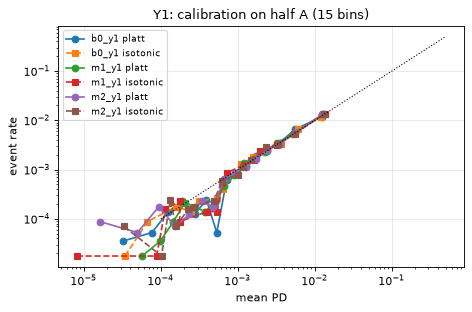

auc  brier  log_loss    ece  ece_norm  cal_slope  cal_intercept
task model         calibrator                                                                   
y1   b0_y1         platt      0.8518 0.0020    0.0125 0.0001    0.0567     1.0360        -0.0095
                   isotonic   0.8511 0.0020    0.0125 0.0001    0.0560     1.0177        -0.0091
     m1_y1         platt      0.8629 0.0020    0.0123 0.0001    0.0667     1.0503        -0.0077
                   isotonic   0.8625 0.0020    0.0123 0.0001    0.0463     1.0284        -0.0087
     m2_y1         platt      0.8579 0.0020    0.0124 0.0001    0.0513     1.0544        -0.0073
                   isotonic   0.8570 0.0020    0.0124 0.0001    0.0539     1.0288        -0.0075
     m1_y1_noomega platt      0.8635 0.0020    0.0123 0.0001    0.0637     1.0508        -0.0075
                   isotonic   0.8632 0.0020    0.0123 0.0001    0.0650     1.0320        -0.0083
     h3_static_y1  platt      0.8491 0.0020    0.0126 0.0002    0.0841     1.0690        -0.0070
                   isotonic   0.8482 0.0020    0.0126 0.0001    0.0629     1.0435        -0.0071
     h3_full_y1    platt      0.8630 0.0020    0.0123 0.0001    0.0690     1.0506        -0.0084
                   isotonic   0.8624 0.0020    0.0123 0.0001    0.0605     1.0320        -0.0092

In [3]:
rows, cals = [], {}
fig, axes = plt.subplots(1, len(val), figsize=(6 * len(val), 4), squeeze=False)
for ax, (task, v) in zip(axes[0], val.items()):
    a, b = v.filter(pl.col("half") == "A"), v.filter(pl.col("half") == "B")
    for name in MODELS[task]:
        for cname, C in (("platt", Platt), ("isotonic", Isotonic)):
            cal = C().fit(b[name].to_numpy(), b[task].to_numpy())
            cals[(name, cname)] = cal
            pa = cal.predict(a[name].to_numpy())
            rows.append({"task": task, "model": name, "calibrator": cname, **all_metrics(a[task].to_numpy(), pa)})
            if name in ("m1_y1", "m2_y1", "b0_y1"):
                mp, er = calibration_curve(a[task].to_numpy(), pa, bins=15)
                ax.loglog(mp, er, "o-" if cname == "platt" else "s--", label=f"{name} {cname}")
    ax.plot([1e-4, 0.5], [1e-4, 0.5], "k:", lw=1); ax.set_title(f"{task.upper()}: calibration on half A (15 bins)")
    ax.set_xlabel("mean PD"); ax.set_ylabel("event rate"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
calib = pd.DataFrame(rows)
calib.to_csv(MODELING_DIR / "validation_calibration.csv", index=False)
calib.set_index(["task", "model", "calibrator"])[["auc", "brier", "log_loss", "ece", "ece_norm", "cal_slope", "cal_intercept"]]

**EN. How to read.** Both calibrators work for every model: after Platt the calibration slope is 1.04–1.07 and the intercept −0.007…−0.010, ECE 0.0001–0.0002 (5–8 % of the event rate); the mean PD equals the event rate (0.20 %). Isotonic gives a slope closer to 1 (1.02–1.04) at an AUC 0.0004–0.001 lower (the step function creates ties). **Platt stays the main calibrator** (linear in logits, keeps SHAP contributions additive); isotonic is the sensitivity check. A slope slightly above 1 means the calibrated PDs are slightly too compressed; the effect on the alert list is small.

**RU. Как читать.** Оба калибратора работают у всех моделей: после Платта наклон калибровки 1,04–1,07, сдвиг −0,007…−0,010, ECE 0,0001–0,0002 (5–8 % доли событий); средняя PD равна доле событий (0,20 %). Изотоническая регрессия даёт наклон ближе к 1 (1,02–1,04) при AUC ниже на 0,0004–0,001 (ступенчатая функция создаёт совпадающие значения). **Основной калибратор остаётся Платт** (линеен в логитах, сохраняет аддитивность вкладов SHAP); изотоническая — проверка чувствительности. Наклон чуть выше 1 означает, что откалиброванные PD немного «сжаты»; на список тревоги это влияет мало.

### 2. LGD and expected loss / LGD и ожидаемый убыток

**EN.** LGD segments (mean realised loss rate of 68 k liquidations completed by 2015-06) applied by the **current** MTM LTV of the loan at t; EAD = current balance. Table: share of validation rows and of realised Y1 loss per segment.

**RU.** Сегменты LGD (средняя доля реализованного убытка по 68 тыс. ликвидаций, завершённых до 2015-06) применяются по **текущему** MTM LTV кредита на t; EAD — текущий ОД. Таблица: доля строк validation и фактического убытка Y1 по сегментам.

In [4]:
v = val["y1"].with_columns((pl.col("y1") * pl.col("lgd") * pl.col("upb")).alias("loss"))
seg = v.group_by("lgd").agg(pl.len().alias("rows"), pl.col("y1").mean().alias("y1_rate"), pl.col("upb").mean().alias("mean_ead"),
                            pl.col("loss").sum().alias("loss")).with_columns(
    (pl.col("rows") / pl.col("rows").sum()).alias("share_rows"), (pl.col("loss") / pl.col("loss").sum()).alias("share_loss")).sort("lgd")
display(lgd_table("base")[["segment", "liquidations", "lgd_mean"]].T)
seg.to_pandas()

,0,1,2,3,4,5,6,7,8,9,10,11
segment,NJ:<60|<60,NJ:60|60-80,NJ:80|80-90,NJ:90|90-100,NJ:100|100-120,NJ:120+|120+,J:<60|<60,J:60|60-80,J:80|80-90,J:90|90-100,J:100|100-120,J:120+|120+
liquidations,1236,8773,8418,8300,8843,6717,944,6381,5825,4870,4894,3015
lgd_mean,0.3200,0.3987,0.4225,0.4370,0.4732,0.5136,0.4889,0.5198,0.5265,0.5316,0.5554,0.5795


,lgd,rows,y1_rate,mean_ead,loss,share_rows,share_loss
0,0.3200,444971,0.0010,"189,251.3315","21,847,502.4335",0.2607,0.0788
1,0.3987,474225,0.0021,"221,902.0348","79,911,938.2929",0.2778,0.2882
2,0.4225,127475,0.0037,"227,709.4207","46,129,450.3794",0.0747,0.1663
3,0.4370,36132,0.0039,"221,977.7298","13,470,800.9162",0.0212,0.0486
4,0.4425,111,0.0000,"216,347.3233",0.0000,0.0001,0.0000
5,0.4732,2,0.0000,"89,802.6100",0.0000,0.0000,0.0000
6,0.4889,207440,0.0012,"153,818.1588","17,158,158.9223",0.1215,0.0619
7,0.5198,288676,0.0023,"188,076.6252","54,631,190.6682",0.1691,0.1970
8,0.5265,94725,0.0034,"193,068.9362","30,812,831.3595",0.0555,0.1111
9,0.5316,33240,0.0039,"188,911.7100","13,364,784.7319",0.0195,0.0482


### 3. Alert list: captured events and EL / Список тревоги: пойманные события и EL

**EN.** For every Y1 model (Platt-calibrated PD) on half A, at the main threshold PD ≥ 0.01 and at 0.02 / 0.005: how many observations are on the list, the precision (share of defaults on the list), the share of all events and the share of realised EL that fall on the list. Then the **validation preview of H4**: M1 with the exposure weight ω vs M1 without it — Δ captured EL share with a 95 % cluster bootstrap CI by loan (B = 1000) and the difference in calibration slope and intercept. The decision on H4 is taken on test.

**RU.** Для каждой модели Y1 (PD после Платта) на половине A при основном пороге PD ≥ 0,01 и при 0,02 / 0,005: сколько наблюдений в списке, точность (доля дефолтов в списке), доля всех событий и доля фактического EL, попавшие в список. Затем **предварительная проверка H4 на validation**: M1 с весом по ОД ω против M1 без него — Δ доли пойманного EL с 95 %-м интервалом кластерного bootstrap по кредиту (B = 1000) и разница наклона и сдвига калибровки. Решение по H4 принимается на test.

In [5]:
a = val["y1"].filter(pl.col("half") == "A")
y, lgd, ead = a["y1"].to_numpy(), a["lgd"].to_numpy(), a["upb"].to_numpy()
pd_ = {n: cals[(n, "platt")].predict(a[n].to_numpy()) for n in MODELS["y1"]}
rows = []
for thr in THRESHOLDS:
    for n in MODELS["y1"]:
        al = alert_mask(pd_[n], thr)
        rows.append({"threshold": thr, "model": n, "alerts": int(al.sum()), "alert_share": float(al.mean()),
                     "precision": float(y[al].mean()) if al.any() else np.nan,
                     "event_share": captured_event_share(y, al), "el_share": captured_el_share(y, al, lgd, ead)})
alerts = pd.DataFrame(rows)
alerts.to_csv(MODELING_DIR / "validation_alert_capture.csv", index=False)
alerts.set_index(["threshold", "model"])

alerts  alert_share  precision  event_share  el_share
threshold model                                                               
0.0100    b0_y1           32140       0.0377     0.0133       0.2531    0.2518
          m1_y1           30473       0.0357     0.0177       0.3186    0.3299
          m2_y1           31827       0.0373     0.0176       0.3310    0.3472
          m1_y1_noomega   30811       0.0361     0.0173       0.3145    0.3270
          h3_static_y1    30647       0.0359     0.0147       0.2667    0.2687
          h3_full_y1      30801       0.0361     0.0171       0.3103    0.3269
0.0200    b0_y1            4803       0.0056     0.0210       0.0596    0.0626
          m1_y1            7196       0.0084     0.0293       0.1245    0.1308
          m2_y1            5641       0.0066     0.0280       0.0932    0.1042
          m1_y1_noomega    7092       0.0083     0.0296       0.1239    0.1318
          h3_static_y1     3697       0.0043     0.0233       0.0507    0.0543
          h3_full_y1       7220       0.0085     0.0305       0.1298    0.1418
0.0050    b0_y1           95009       0.1114     0.0100       0.5617    0.5561
          m1_y1           86820       0.1018     0.0111       0.5664    0.5551
          m2_y1           94324       0.1106     0.0102       0.5693    0.5728
          m1_y1_noomega   87065       0.1021     0.0111       0.5687    0.5580
          h3_static_y1    92305       0.1082     0.0099       0.5392    0.5460
          h3_full_y1      87200       0.1022     0.0110       0.5652    0.5599

In [6]:
# validation preview of H4: M1 with the exposure weight vs M1 without it, same alert rule
h4_frame = a.select("loan_identifier", "upb", "lgd", "y1").with_columns(
    pl.Series("pd_with", pd_["m1_y1"]), pl.Series("pd_without", pd_["m1_y1_noomega"]))
h4 = pd.DataFrame({thr: h4_check(h4_frame, "y1", "pd_with", "pd_without", threshold=thr, b=1000, seed=SEED)
                   for thr in THRESHOLDS})
h4.to_csv(MODELING_DIR / "validation_h4_preview.csv")
h4


,0.0100,0.0200,0.0050
el_share_with,0.3299,0.1308,0.5551
el_share_without,0.3270,0.1318,0.5580
delta,0.0029,-0.0010,-0.0028
delta_lo,-0.0097,-0.0095,-0.0111
delta_hi,0.0157,0.0059,0.0047
slope_with,1.0503,1.0503,1.0503
slope_without,1.0508,1.0508,1.0508
d_slope,-0.0005,-0.0005,-0.0005
intercept_with,-0.0077,-0.0077,-0.0077
intercept_without,-0.0075,-0.0075,-0.0075


**EN. How to read.** At **PD ≥ 0.01** about 3.6 % of observations are on the list (30.5 k of 853 k on half A). **M1 catches 32 % of the defaults and 33 % of the realised loss** with precision 1.8 % (nine times the average 0.20 %); M2 33 % / 35 %, the full H3 model 31 % / 33 %, the static H3 model 27 % / 27 %, the scorecard B0 25 % / 25 %. At 0.02 the list shrinks to 0.8 % and M1 catches 12 % of defaults (precision 2.9 %); at 0.005 it grows to about 10 % and catches 57 % (precision 1.1 %). **Validation preview of H4:** with ω the captured EL share is 33.0 %, without ω 32.7 %: Δ = +0.3 p.p. [−1.0; +1.6] — the CI includes 0, so the EL part of H4 is not met; the calibration part is met (Δslope −0.0005, Δintercept −0.0001). The same at 0.02 and 0.005 (Δ −0.1 and −0.3 p.p.). The exposure weight does not change which loans are on the list: verdict "partial" on validation; test decides.

**RU. Как читать.** При **PD ≥ 0,01** в списке около 3,6 % наблюдений (30,5 тыс. из 853 тыс. на половине A). **M1 ловит 32 % дефолтов и 33 % фактического убытка** при точности 1,8 % (в девять раз выше средней доли 0,20 %); M2 — 33 % / 35 %, полная модель H3 — 31 % / 33 %, статическая модель H3 — 27 % / 27 %, скоркарта B0 — 25 % / 25 %. При 0,02 список сокращается до 0,8 %, и M1 ловит 12 % дефолтов (точность 2,9 %); при 0,005 он растёт примерно до 10 % и ловит 57 % (точность 1,1 %). **Предварительная проверка H4:** с весом ω доля пойманного EL — 33,0 %, без него — 32,7 %: Δ = +0,3 п.п. [−1,0; +1,6] — интервал включает 0, значит, часть H4 про EL не выполнена; часть про калибровку выполнена (Δнаклона −0,0005, Δсдвига −0,0001). То же при 0,02 и 0,005 (Δ −0,1 и −0,3 п.п.). Вес по ОД не меняет состав списка: на validation вердикт «частично»; решение — на test.

### 4. Lead time / Lead time

**EN.** Event loans of validation (both halves); event month E = t + months to the first event. All quarterly snapshots from 2015-09 to 2017-12 (12 months before the first possible event up to the last) are scored, including dates in the embargo gaps (features only, no labels), on the label's population, without the 20 % holdout loans (as in validation) and without disaster-affected rows. Alert = calibrated PD ≥ threshold at that date (main 0.01; 0.02 and 0.005 as sensitivity); lead time = E − first alert date within [E − 12, E − 1]; median over alerted loans with a bootstrap CI over event loans. B0 is scored with the same features as M1.

**RU.** Кредиты validation с событием (обе половины); месяц события E = t + число месяцев до первого события. Оцениваются все квартальные снимки с 2015-09 по 2017-12 (от 12 месяцев до самого раннего события до последнего), включая даты в эмбарго-зазорах (только признаки, без меток), на популяции метки, без отложенных 20 % кредитов (как в validation) и без затронутых бедствиями наблюдений. Тревога — калиброванная PD ≥ порога на эту дату (основной 0,01; 0,02 и 0,005 — чувствительность); lead time = E − первая дата тревоги в [E − 12, E − 1]; медиана по кредитам с тревогой, bootstrap-интервал по кредитам с событием. B0 оценивается на тех же признаках, что и M1.

In [7]:
from xai_ews.config import feature_config
SEL = feature_config()["selected"]
lt_rows, lt_frames = [], {}
ev = event_months(val["y1"], "y1", EVENT_MONTH["y1"])
for n in MODELS["y1"]:
    feats, cats = (SEL["features"], SEL["categorical"]) if n.startswith("b0_") else \
        (registry.meta(n)["features"], registry.meta(n)["categorical"])
    snap = load_snapshots("2015-09", "2017-12", "y1", feats, cats, holdout=False)
    scored = snap.select("loan_identifier", "m").with_columns(
        pl.Series("pd", cals[(n, "platt")].predict(registry.predict_any(n, snap))))
    del snap; gc.collect()
    for thr in THRESHOLDS:
        lt = lead_times(ev, scored, thr)
        lt_frames[(n, thr)] = lt
        ci = bootstrap_median(lt, b=1000, seed=SEED)
        lt_rows.append({"model": n, "threshold": thr, **summarise(lt), "median_lo": ci["lo"], "median_hi": ci["hi"],
                        "alert_share_snapshots": float(alert_mask(scored["pd"].to_numpy(), thr).mean())})
    print(n, "scored", scored.height, flush=True)
leadtime = pd.DataFrame(lt_rows)
leadtime.to_csv(MODELING_DIR / "validation_lead_time.csv", index=False)
leadtime.set_index(["threshold", "model"])

b0_y1 scored 4556279


m1_y1 scored 4556279


m2_y1 scored 4556279


m1_y1_noomega scored 4556279


h3_static_y1 scored 4556279


h3_full_y1 scored 4556279


,,event_loans,alerted,alert_rate,median_lead,mean_lead,share_ge6,median_lead_missed0,median_lo,median_hi,alert_share_snapshots
threshold,model,,,,,,,,,,
0.0100,b0_y1,2047,622,0.3039,10.0000,9.4968,0.8907,0.0000,10.0000,10.0000,0.0368
0.0200,b0_y1,2047,153,0.0747,10.0000,9.2876,0.9085,0.0000,10.0000,10.0000,0.0051
0.0050,b0_y1,2047,1222,0.5970,10.0000,9.6727,0.9083,7.0000,10.0000,10.0000,0.1105
0.0100,m1_y1,2047,759,0.3708,10.0000,9.0817,0.8485,0.0000,10.0000,10.0000,0.0367
0.0200,m1_y1,2047,331,0.1617,9.0000,8.4562,0.7915,0.0000,9.0000,10.0000,0.0092
0.0050,m1_y1,2047,1264,0.6175,10.0000,9.5459,0.8956,7.0000,10.0000,10.0000,0.1029
0.0100,m2_y1,2047,756,0.3693,10.0000,9.1892,0.8664,0.0000,10.0000,10.0000,0.0363
0.0200,m2_y1,2047,259,0.1265,9.0000,8.5521,0.8147,0.0000,9.0000,10.0000,0.0062
0.0050,m2_y1,2047,1269,0.6199,10.0000,9.6225,0.9015,8.0000,10.0000,10.0000,0.1111


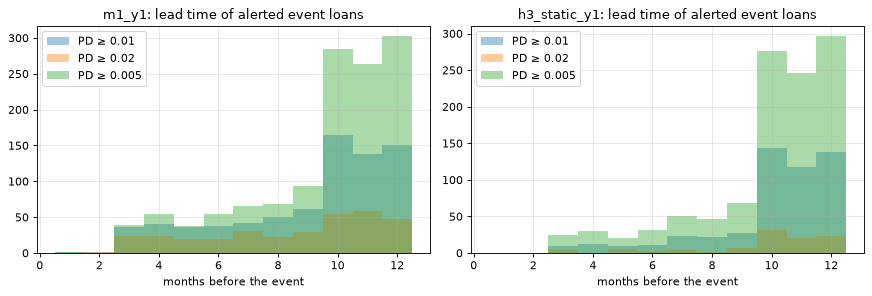

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(axes, ("m1_y1", "h3_static_y1")):
    for thr in THRESHOLDS:
        l = lt_frames[(n, thr)]["lead"].drop_nulls().to_numpy()
        ax.hist(l, bins=np.arange(0.5, 13.5, 1), alpha=0.4, label=f"PD ≥ {thr}")
    ax.set_title(f"{n}: lead time of alerted event loans"); ax.set_xlabel("months before the event"); ax.legend()
plt.tight_layout(); plt.show()

**EN. How to read.** Validation has 2,047 event loans. At **PD ≥ 0.01** M1 alerts **37 %** of them before the default; the median lead time of the alerted loans is **10 months** (95 % CI [10; 10]), 85 % are alerted at least 6 months ahead. M2 and the full H3 model are the same (37 %), B0 30 %, the static H3 model 25 %. At 0.005 about 62 % of event loans are alerted, at 0.02 about 16 % (median 9 months). **Important for interpreting H3:** the median lead time is 10 months for the static model too. With quarterly snapshots the first alert is usually the first snapshot in the 12-month window: a loan that the model finds risky is on the list from the start, so lead time measures how long a risky loan stays on the list rather than when deterioration becomes visible. The lead-time part of H3 (lower bound ≥ 3 months) therefore passes easily; the informative difference between the static and the full model is the **share of event loans alerted** (25 % vs 37 %) and ΔAUC. The rule is not changed; the report states this limitation.

**RU. Как читать.** В validation 2 047 кредитов с событием. При **PD ≥ 0,01** M1 подаёт тревогу до дефолта по **37 %** из них; медианный lead time у кредитов с тревогой — **10 месяцев** (95 % CI [10; 10]), 85 % получают тревогу не меньше чем за 6 месяцев. У M2 и полной модели H3 так же (37 %), у B0 — 30 %, у статической модели H3 — 25 %. При 0,005 тревогу получают около 62 % кредитов с событием, при 0,02 — около 16 % (медиана 9 месяцев). **Важно для интерпретации H3:** у статической модели медианный lead time тоже 10 месяцев. При квартальных снимках первая тревога обычно приходится на первый снимок 12-месячного окна: кредит, который модель считает рискованным, в списке с самого начала, поэтому lead time измеряет, сколько рискованный кредит держится в списке, а не когда становится видно ухудшение. Поэтому часть H3 про lead time (нижняя граница ≥ 3 мес.) выполняется легко, а информативная разница между статической и полной моделью — **доля кредитов с событием, получивших тревогу** (25 % против 37 %), и ΔAUC. Правило не меняется; ограничение указывается в отчёте.

### 5. Validation preview of H3 / Предварительная проверка H3 на validation

**EN.** H3 compares the static model (16 features known at origination) with the static + selected dynamic model (23 features), both tuned and calibrated the same way: ΔAUC with a cluster bootstrap by loan and DeLong on one snapshot per loan (half A), and the lead time at the main threshold (paired bootstrap over event loans). The decision is taken on test (03_6).

**RU.** H3 сравнивает статическую модель (16 признаков, известных при выдаче) со статической + отобранными динамическими (23 признака); обе подобраны и откалиброваны одинаково: ΔAUC с кластерным bootstrap по кредиту и DeLong на одном снимке на кредит (половина A) и lead time при основном пороге (парный bootstrap по кредитам с событием). Решение принимается на test (03_6).

In [9]:
h3_auc = pairwise(y, {n: a[n].to_numpy() for n in ("h3_full_y1", "h3_static_y1")}, a["loan_identifier"].to_numpy(),
                  [("h3_full_y1", "h3_static_y1")], b=1000, seed=SEED)
h3_lt = paired_bootstrap(lt_frames[("h3_full_y1", THRESHOLDS[0])], lt_frames[("h3_static_y1", THRESHOLDS[0])], b=1000, seed=SEED)
h3_auc.to_csv(MODELING_DIR / "validation_h3_preview_auc.csv", index=False)
h3_lt.to_csv(MODELING_DIR / "validation_h3_preview_leadtime.csv")
display(h3_auc)
h3_lt

,pair,delta_auc,lo,hi,share_le_0,delong_delta_one_snapshot,delong_p,one_snapshot_rows,one_snapshot_events,delong_p_holm
0,h3_full_y1 − h3_static_y1,0.0139,0.0094,0.0180,0.0000,0.0151,0.0000,287102,793,0.0000


,delta,lo,hi
alert_rate,0.1202,0.1021,0.1383
median_lead,0.0000,-1.0000,0.0000


**EN. How to read.** The dynamic features add **+0.014 AUC** [0.009; 0.018] to the static model (DeLong on one snapshot per loan +0.015, p < 0.001), and **12 p.p. more event loans** get an alert at PD ≥ 0.01 (+10.2…+13.8); the median lead time of the alerted loans does not change (Δ 0 [−1; 0]). On validation both parts of H3 hold: ΔAUC > 0 with p < 0.05, and the lower bound of the median lead time (10 months) is above 3 months.

**RU. Как читать.** Динамические признаки добавляют к статической модели **+0,014 AUC** [0,009; 0,018] (DeLong на одном снимке на кредит +0,015, p < 0,001), и тревогу при PD ≥ 0,01 получают на **12 п.п. больше кредитов с событием** (+10,2…+13,8); медианный lead time кредитов с тревогой не меняется (Δ 0 [−1; 0]). На validation обе части H3 выполняются: ΔAUC > 0 при p < 0,05, нижняя граница медианного lead time (10 месяцев) выше 3 месяцев.

### 6. AUC inside FICO bands / AUC внутри групп FICO

**EN.** How well each model orders loans of borrowers with the same FICO band (< 680 incl. missing, 680–739, ≥ 740 — the bands of H2), half A. The part of the AUC that comes only from separating the bands drops out. Reported for the final models on validation and test.

**RU.** Насколько хорошо каждая модель упорядочивает кредиты заёмщиков из одной группы FICO (< 680 вместе с пропусками, 680–739, ≥ 740 — группы H2), половина A. Часть AUC, которая получается только от разделения групп, убирается. Приводится для итоговых моделей на validation и test.

In [10]:
within = pd.concat([auc_within_segments(y, a[n].to_numpy(), a[FICO].to_numpy()).assign(model=n) for n in MODELS["y1"]],
                   ignore_index=True)
within.to_csv(MODELING_DIR / "validation_auc_within_fico.csv", index=False)
within.pivot(index="model", columns="segment", values="auc")[["<680", "680-739", ">=740"]].join(
    pd.Series({n: all_metrics(y, pd_[n])["auc"] for n in MODELS["y1"]}, name="auc_all"))

,<680,680-739,>=740,auc_all
model,,,,
b0_y1,0.6562,0.7315,0.8282,0.8518
h3_full_y1,0.7093,0.7527,0.8388,0.8630
h3_static_y1,0.6517,0.7298,0.8122,0.8491
m1_y1,0.7102,0.7479,0.8399,0.8629
m1_y1_noomega,0.7094,0.7487,0.8432,0.8635
m2_y1,0.6995,0.7438,0.8291,0.8579


**EN. How to read.** Inside each FICO band the models still separate defaults from non-defaults: M1 AUC 0.71 (< 680), 0.75 (680–739), 0.84 (≥ 740); M2 0.70 / 0.74 / 0.83; B0 0.66 / 0.73 / 0.83; the static H3 model 0.65 / 0.73 / 0.81. The gain of M1 over the scorecard and over the static model is largest among the riskiest borrowers (< 680: +0.05 and +0.06), i.e. the dynamic features help most where defaults are frequent.

**RU. Как читать.** Внутри каждой группы FICO модели по-прежнему отделяют дефолты от недефолтов: M1 — AUC 0,71 (< 680), 0,75 (680–739), 0,84 (≥ 740); M2 — 0,70 / 0,74 / 0,83; B0 — 0,66 / 0,73 / 0,83; статическая модель H3 — 0,65 / 0,73 / 0,81. Преимущество M1 над скоркартой и над статической моделью больше всего у самых рискованных заёмщиков (< 680: +0,05 и +0,06), то есть динамические признаки помогают сильнее там, где дефолты часты.

**EN. Fixed for test.** Calibrator: Platt on half B (isotonic as sensitivity). LGD: segments by current MTM LTV × judicial state, missing LTV → the group mean. EL = PD × LGD × UPB. Alert list: calibrated PD ≥ 0.01 (main), 0.02 and 0.005 (sensitivity). Captured EL share as defined in the protocol (section 7). Lead time: first alert within [E − 12, E − 1] on quarterly snapshots, test window 2017-06 … 2019-09, median over alerted loans with a bootstrap CI over event loans. AUC inside the FICO bands is reported next to the overall AUC. Nothing here was tuned towards a hypothesis outcome; the H4 and H3 previews are reported as they are.

**RU. Зафиксировано для test.** Калибратор — Платт на половине B (изотоническая — чувствительность). LGD — сегменты по текущему MTM LTV × судебный штат, пропуск LTV → среднее группы. EL = PD × LGD × ОД. Список тревоги — калиброванная PD ≥ 0,01 (основной), 0,02 и 0,005 (чувствительность). Доля пойманного EL — по определению протокола (раздел 7). Lead time — первая тревога в [E − 12, E − 1] на квартальных снимках, окно test 2017-06 … 2019-09, медиана по кредитам с тревогой, bootstrap-интервал по кредитам с событием. AUC внутри групп FICO приводится рядом с общим AUC. Ничего здесь не подгонялось под исход гипотез; предварительные результаты по H4 и H3 приведены как есть.